In [1]:

!apt-get -qq update
!apt-get -qq install -y ffmpeg
%pip install -q -U openai-whisper


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 48.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:

import sys
import torch
import whisper

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Whisper imported successfully")
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


Python version: 3.13.15
PyTorch version: 2.11.0+cu130
Whisper imported successfully
GPU available: True
GPU name: Tesla T4


In [9]:

from google.colab import files

uploaded = files.upload()


Saving Recording.m4a to Recording (1).m4a


In [11]:

import os

audio_files = list(uploaded.keys())

print("Uploaded files:", audio_files)

if not audio_files:
    raise ValueError("No file was uploaded.")

audio_path = audio_files[0]

print("Selected file:", audio_path)
print("File size:", round(os.path.getsize(audio_path) / 1024, 2), "KB")


Uploaded files: ['Recording (1).m4a']
Selected file: Recording (1).m4a
File size: 53.46 KB


In [12]:
import librosa
import numpy as np
import os

# Load metadata and audio using librosa
# sr=None preserves the native sampling rate
audio, sample_rate = librosa.load(audio_path, sr=None)
duration = librosa.get_duration(y=audio, sr=sample_rate)
channels = 1 if len(audio.shape) == 1 else audio.shape[0]

print("File format: M4A (via Librosa)")
print("Sample rate:", sample_rate, "Hz")
print("Number of channels:", channels)
print("Duration:", round(duration, 2), "seconds")

if duration <= 0:
    raise ValueError("The audio file is empty.")

if duration > 600:
    raise ValueError("Please use an audio recording shorter than 10 minutes.")

if audio.size == 0 or not np.isfinite(audio).all():
    raise ValueError("The audio contains no usable samples.")

print("Audio validation successful.")
print("Audio shape:", audio.shape)

File format: M4A (via Librosa)
Sample rate: 16000 Hz
Number of channels: 1
Duration: 11.39 seconds
Audio validation successful.
Audio shape: (182272,)


/tmp/ipykernel_1352/1318736863.py:7: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sample_rate = librosa.load(audio_path, sr=None)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


In [13]:

import whisper

model = whisper.load_model("base")

print("Whisper model loaded successfully.")


Whisper model loaded successfully.


In [14]:

result = model.transcribe(audio_path)

transcript = result["text"].strip()

print("Recognized Transcript:")
print(transcript)


Recognized Transcript:
Complete my machine learning task tomorrow and set up SQL questions by Friday.


In [15]:

import re

original_transcript = transcript

normalized_transcript = re.sub(r"\s+", " ", original_transcript).strip()

print("Original transcript:")
print(original_transcript)

print("\nNormalized transcript:")
print(normalized_transcript)


Original transcript:
Complete my machine learning task tomorrow and set up SQL questions by Friday.

Normalized transcript:
Complete my machine learning task tomorrow and set up SQL questions by Friday.


In [16]:

sentences = re.split(r"(?<=[.!?])\s+", normalized_transcript)

sentences = [sentence.strip() for sentence in sentences if sentence.strip()]

print("Sentences identified:")

for sentence in sentences:
    print(sentence)


Sentences identified:
Complete my machine learning task tomorrow and set up SQL questions by Friday.


In [17]:

action_verbs = [
    "complete", "prepare", "study", "call", "send",
    "review", "attend", "upload", "finish", "submit",
    "create", "write", "read", "learn", "set up"
]

print("Supported actions:", action_verbs)


Supported actions: ['complete', 'prepare', 'study', 'call', 'send', 'review', 'attend', 'upload', 'finish', 'submit', 'create', 'write', 'read', 'learn', 'set up']


In [18]:

def extract_tasks(text):
    text = re.sub(r"\s+", " ", text).strip()
    parts = re.split(r"\b(?:and then|then|also|and)\b", text, flags=re.IGNORECASE)

    tasks = []

    for part in parts:
        part = part.strip(" ,.!?")

        if not part:
            continue

        if any(re.search(r"\b" + re.escape(verb) + r"\b", part, re.IGNORECASE) for verb in action_verbs):
            tasks.append(part)

    return tasks


tasks = extract_tasks(normalized_transcript)

for index, task in enumerate(tasks, start=1):
    print(f"Task {index}: {task}")


Task 1: Complete my machine learning task tomorrow
Task 2: set up SQL questions by Friday


In [19]:

deadline_patterns = [
    r"\bby\s+next\s+(?:week|month|monday|tuesday|wednesday|thursday|friday|saturday|sunday)\b",
    r"\bnext\s+(?:week|month|monday|tuesday|wednesday|thursday|friday|saturday|sunday)\b",
    r"\bthis\s+(?:evening|afternoon|morning|weekend)\b",
    r"\bin\s+\d+\s+days?\b",
    r"\btomorrow\b",
    r"\btonight\b",
    r"\btoday\b",
    r"\bby\s+(?:monday|tuesday|wednesday|thursday|friday|saturday|sunday)\b",
    r"\b(?:monday|tuesday|wednesday|thursday|friday|saturday|sunday)\b",
    r"\bnext\s+month\b",
    r"\blater\b",
    r"\beventually\b"
]

print("Deadline patterns defined:", len(deadline_patterns))


Deadline patterns defined: 12


In [20]:

def extract_deadline(task):
    for pattern in deadline_patterns:
        match = re.search(pattern, task, re.IGNORECASE)

        if match:
            deadline = match.group(0)
            deadline = re.sub(r"^by\s+", "", deadline, flags=re.IGNORECASE)

            clean_task = re.sub(pattern, "", task, flags=re.IGNORECASE)
            clean_task = re.sub(r"\s+", " ", clean_task).strip(" ,.!?")

            return clean_task, deadline.title()

    return task.strip(" ,.!?"), "Not specified"


In [21]:

test_task = "Complete my machine learning task tomorrow"

clean_task, deadline = extract_deadline(test_task)

print("Task:", clean_task)
print("Deadline:", deadline)


Task: Complete my machine learning task
Deadline: Tomorrow


In [22]:

task_deadlines = []

for task in tasks:
    clean_task, deadline = extract_deadline(task)

    task_deadlines.append({
        "Task Description": clean_task,
        "Deadline": deadline
    })

for item in task_deadlines:
    print("Task:", item["Task Description"])
    print("Deadline:", item["Deadline"])
    print()


Task: Complete my machine learning task
Deadline: Tomorrow

Task: set up SQL questions
Deadline: Friday



In [23]:

test_cases = [
    "Submit the report today",
    "Review the presentation by Friday",
    "Study for the exam in 2 days",
    "Call my project guide later",
    "Read the research paper"
]

for test in test_cases:
    clean_task, deadline = extract_deadline(test)
    print(f"Input: {test}")
    print(f"Task: {clean_task} | Deadline: {deadline}")
    print()


Input: Submit the report today
Task: Submit the report | Deadline: Today

Input: Review the presentation by Friday
Task: Review the presentation | Deadline: Friday

Input: Study for the exam in 2 days
Task: Study for the exam | Deadline: In 2 Days

Input: Call my project guide later
Task: Call my project guide | Deadline: Later

Input: Read the research paper
Task: Read the research paper | Deadline: Not specified



In [24]:

high_priority_words = [
    "urgent", "urgently", "asap", "immediately", "critical"
]

medium_priority_words = [
    "soon", "this week", "by tomorrow", "tomorrow",
    "today", "tonight", "this evening", "in 2 days",
    "in 3 days"
]

low_priority_words = [
    "later", "eventually", "when possible"
]

print("Priority rules initialized.")


Priority rules initialized.


In [25]:

def classify_priority(task, deadline):
    text = (task + " " + deadline).lower()

    if any(re.search(r"\b" + re.escape(word) + r"\b", text) for word in high_priority_words):
        return "High"

    if any(re.search(r"\b" + re.escape(word) + r"\b", text) for word in low_priority_words):
        return "Low"

    if any(re.search(r"\b" + re.escape(word) + r"\b", text) for word in medium_priority_words):
        return "Medium"

    if deadline.lower() != "not specified":
        return "Medium"

    return "Medium"


In [26]:

priority_tests = [
    ("Submit the report urgently", "Not specified"),
    ("Complete the ML assignment", "Tomorrow"),
    ("Call my project guide", "Later"),
    ("Read the research paper", "Not specified")
]

for task, deadline in priority_tests:
    priority = classify_priority(task, deadline)
    print(f"Task: {task} | Deadline: {deadline} | Priority: {priority}")


Task: Submit the report urgently | Deadline: Not specified | Priority: High
Task: Complete the ML assignment | Deadline: Tomorrow | Priority: Medium
Task: Call my project guide | Deadline: Later | Priority: Low
Task: Read the research paper | Deadline: Not specified | Priority: Medium


In [27]:

for item in task_deadlines:
    item["Priority"] = classify_priority(
        item["Task Description"],
        item["Deadline"]
    )

for item in task_deadlines:
    print("Task:", item["Task Description"])
    print("Deadline:", item["Deadline"])
    print("Priority:", item["Priority"])
    print()


Task: Complete my machine learning task
Deadline: Tomorrow
Priority: Medium

Task: set up SQL questions
Deadline: Friday
Priority: Medium



In [29]:
import pandas as pd

# Create the DataFrame from the task_deadlines list
df = pd.DataFrame(task_deadlines)

# Initialize default 'Completion Status' column since it is referenced below
if "Completion Status" not in df.columns:
    df["Completion Status"] = "Pending"

total_tasks = len(df)

priority_counts = df["Priority"].value_counts()

pending_tasks = (df["Completion Status"] == "Pending").sum()

print("Total tasks:", total_tasks)
print("Pending tasks:", pending_tasks)
print("\nTasks by priority:")
print(priority_counts)

Total tasks: 2
Pending tasks: 2

Tasks by priority:
Priority
Medium    2
Name: count, dtype: int64


In [30]:

csv_path = "voice2task_tasks.csv"

df.to_csv(csv_path, index=False)

print("CSV file created:", csv_path)


CSV file created: voice2task_tasks.csv


In [31]:

from google.colab import files

files.download(csv_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

excel_path = "voice2task_tasks.xlsx"

df.to_excel(excel_path, index=False)

print("Excel file created:", excel_path)


Excel file created: voice2task_tasks.xlsx


In [33]:

%pip install -q gradio


In [34]:

import pandas as pd
import os
import tempfile

def process_audio(audio_file):
    if audio_file is None:
        return "Please upload an audio file.", pd.DataFrame(), "No tasks processed.", None

    result = model.transcribe(audio_file, task="transcribe")
    transcript = result["text"].strip()

    if not transcript:
        return "No speech recognized. Please try another recording.", pd.DataFrame(), "No tasks found.", None

    normalized_text = re.sub(r"\s+", " ", transcript).strip()
    extracted_tasks = extract_tasks(normalized_text)

    task_rows = []

    for task in extracted_tasks:
        clean_task, deadline = extract_deadline(task)
        priority = classify_priority(clean_task, deadline)

        task_rows.append({
            "Task Description": clean_task,
            "Deadline": deadline,
            "Priority": priority,
            "Completion Status": "Pending"
        })

    columns = ["Task ID", "Task Description", "Deadline", "Priority", "Completion Status"]
    df_result = pd.DataFrame(task_rows)

    if df_result.empty:
        df_result = pd.DataFrame(columns=columns)
        return transcript, df_result, "No actionable tasks detected.", None

    df_result = df_result.drop_duplicates(
        subset=["Task Description"], keep="first"
    ).reset_index(drop=True)

    df_result.insert(
        0, "Task ID",
        [f"T{i:03d}" for i in range(1, len(df_result) + 1)]
    )

    df_result = df_result[columns].fillna("Not specified")

    priority_counts = df_result["Priority"].value_counts().to_dict()

    summary = (
        f"Total tasks: {len(df_result)}\n"
        f"Pending tasks: {(df_result['Completion Status'] == 'Pending').sum()}\n"
        f"Priority distribution: {priority_counts}"
    )

    with tempfile.NamedTemporaryFile(
        suffix=".csv", delete=False
    ) as file:
        csv_path = file.name

    df_result.to_csv(csv_path, index=False)

    return transcript, df_result, summary, csv_path


In [38]:

test_cases = [
    {
        "input": "Complete my assignment tomorrow",
        "expected_tasks": 1
    },
    {
        "input": "Prepare SQL questions by Friday",
        "expected_tasks": 1
    },
    {
        "input": "Complete my assignment tomorrow and prepare SQL questions by Friday",
        "expected_tasks": 2
    },
    {
        "input": "Call my project guide later",
        "expected_tasks": 1
    },
    {
        "input": "Submit the report urgently",
        "expected_tasks": 1
    },
    {
        "input": "Read the research paper",
        "expected_tasks": 1
    },
    {
        "input": "Study for the exam in 2 days",
        "expected_tasks": 1
    },
    {
        "input": "Review the presentation tonight",
        "expected_tasks": 1
    },
    {
        "input": "Upload the assignment and then send the report",
        "expected_tasks": 2
    },
    {
        "input": "Finish the project next week",
        "expected_tasks": 1
    }
]

print("Number of test cases:", len(test_cases))


Number of test cases: 10


In [39]:

test_results = []

for case in test_cases:
    extracted = extract_tasks(case["input"])

    actual_count = len(extracted)
    expected_count = case["expected_tasks"]

    test_results.append({
        "Input": case["input"],
        "Expected Tasks": expected_count,
        "Actual Tasks": actual_count,
        "Result": "PASS" if actual_count == expected_count else "FAIL",
        "Extracted Output": " | ".join(extracted)
    })

test_df = pd.DataFrame(test_results)

display(test_df)

print("Passed:", (test_df["Result"] == "PASS").sum())
print("Failed:", (test_df["Result"] == "FAIL").sum())
print("Total:", len(test_df))


,Input,Expected Tasks,Actual Tasks,Result,Extracted Output
0,Complete my assignment tomorrow,1,1,PASS,Complete my assignment tomorrow
1,Prepare SQL questions by Friday,1,1,PASS,Prepare SQL questions by Friday
2,Complete my assignment tomorrow and prepare SQ...,2,2,PASS,Complete my assignment tomorrow | prepare SQL ...
3,Call my project guide later,1,1,PASS,Call my project guide later
4,Submit the report urgently,1,1,PASS,Submit the report urgently
5,Read the research paper,1,1,PASS,Read the research paper
6,Study for the exam in 2 days,1,1,PASS,Study for the exam in 2 days
7,Review the presentation tonight,1,1,PASS,Review the presentation tonight
8,Upload the assignment and then send the report,2,2,PASS,Upload the assignment | send the report
9,Finish the project next week,1,1,PASS,Finish the project next week


Passed: 10
Failed: 0
Total: 10


In [44]:

additional_cases = [
    {"input": "Submit my assignment", "expected_tasks": 1},
    {"input": "Write the project report", "expected_tasks": 1},
    {"input": "Attend the team meeting tomorrow", "expected_tasks": 1},
    {"input": "Create a presentation by Monday", "expected_tasks": 1},
    {"input": "Learn Python this week", "expected_tasks": 1},
    {"input": "Send the email immediately", "expected_tasks": 1},
    {"input": "Review the report and upload the assignment", "expected_tasks": 2},
    {"input": "Study for the exam and prepare notes", "expected_tasks": 2},
    {"input": "Complete the project then call the guide", "expected_tasks": 2},
    {"input": "Read the paper and write a summary", "expected_tasks": 2},
    {"input": "Finish the assignment ASAP", "expected_tasks": 1},
    {"input": "Call my mentor when possible", "expected_tasks": 1},
    {"input": "Prepare slides for the presentation tonight", "expected_tasks": 1},
    {"input": "Upload the file in 3 days", "expected_tasks": 1},
    {"input": "Eventually review the documentation", "expected_tasks": 1},
    {"input": "The weather is pleasant today", "expected_tasks": 0},
    {"input": "I have a meeting tomorrow", "expected_tasks": 0},
    {"input": "The assignment deadline is Friday", "expected_tasks": 0},
    {"input": "The report is complete", "expected_tasks": 0},
    {"input": "Hello, how are you?", "expected_tasks": 0}
]

print("Additional test cases:", len(additional_cases))


Additional test cases: 20


In [42]:

def extract_tasks(text):
    text = re.sub(r"\s+", " ", text).strip()
    parts = re.split(r"\b(?:and then|then|also|and)\b", text, flags=re.IGNORECASE)

    tasks = []

    for part in parts:
        part = part.strip(" ,.!?")

        if not part:
            continue

        if re.match(
            r"^(the|a|an|my|this|that)\b.*\b(is|was|are|were)\s+(complete|completed|finished|done)$",
            part,
            re.IGNORECASE
        ):
            continue

        if any(
            re.search(r"\b" + re.escape(verb) + r"\b", part, re.IGNORECASE)
            for verb in action_verbs
        ):
            tasks.append(part)

    return tasks


In [43]:

print(extract_tasks("The report is complete"))
print(extract_tasks("Complete the report"))


[]
['Complete the report']


In [46]:

all_test_cases = test_cases + additional_cases

test_results = []

for case in all_test_cases:
    extracted = extract_tasks(case["input"])

    expected_count = case["expected_tasks"]
    actual_count = len(extracted)

    test_results.append({
        "Input": case["input"],
        "Expected Tasks": expected_count,
        "Actual Tasks": actual_count,
        "Result": "PASS" if expected_count == actual_count else "FAIL",
        "Extracted Output": " | ".join(extracted)
    })

test_df = pd.DataFrame(test_results)

display(test_df)

print("Passed:", (test_df["Result"] == "PASS").sum())
print("Failed:", (test_df["Result"] == "FAIL").sum())
print("Total:", len(test_df))


,Input,Expected Tasks,Actual Tasks,Result,Extracted Output
0,Complete my assignment tomorrow,1,1,PASS,Complete my assignment tomorrow
1,Prepare SQL questions by Friday,1,1,PASS,Prepare SQL questions by Friday
2,Complete my assignment tomorrow and prepare SQ...,2,2,PASS,Complete my assignment tomorrow | prepare SQL ...
3,Call my project guide later,1,1,PASS,Call my project guide later
4,Submit the report urgently,1,1,PASS,Submit the report urgently
5,Read the research paper,1,1,PASS,Read the research paper
6,Study for the exam in 2 days,1,1,PASS,Study for the exam in 2 days
7,Review the presentation tonight,1,1,PASS,Review the presentation tonight
8,Upload the assignment and then send the report,2,2,PASS,Upload the assignment | send the report
9,Finish the project next week,1,1,PASS,Finish the project next week


Passed: 30
Failed: 0
Total: 30


In [47]:

deadline_tests = [
    {"input": "Complete the assignment today", "task": "Complete the assignment", "deadline": "Today"},
    {"input": "Submit the report tomorrow", "task": "Submit the report", "deadline": "Tomorrow"},
    {"input": "Prepare SQL questions by Friday", "task": "Prepare SQL questions", "deadline": "Friday"},
    {"input": "Attend the meeting next Monday", "task": "Attend the meeting", "deadline": "Next Monday"},
    {"input": "Finish the project in 2 days", "task": "Finish the project", "deadline": "2 Days"},
    {"input": "Review the presentation tonight", "task": "Review the presentation", "deadline": "Tonight"},
    {"input": "Complete the report this evening", "task": "Complete the report", "deadline": "This Evening"},
    {"input": "Call my project guide later", "task": "Call my project guide", "deadline": "Later"},
    {"input": "Read the research paper", "task": "Read the research paper", "deadline": "Not specified"},
    {"input": "Study next week", "task": "Study", "deadline": "Next Week"}
]

print("Deadline test cases:", len(deadline_tests))


Deadline test cases: 10


In [49]:

def extract_deadline(task):
    for pattern in deadline_patterns:
        match = re.search(pattern, task, re.IGNORECASE)

        if match:
            deadline = match.group(0).strip()

            deadline = re.sub(
                r"^(by|in)\s+",
                "",
                deadline,
                flags=re.IGNORECASE
            )

            clean_task = re.sub(
                pattern, "", task, flags=re.IGNORECASE
            )

            clean_task = re.sub(
                r"\s+", " ", clean_task
            ).strip(" ,.!?")

            return clean_task, deadline.title()

    return task.strip(" ,.!?"), "Not specified"


In [50]:

print(extract_deadline("Finish the project in 2 days"))
print(extract_deadline("Prepare SQL questions by Friday"))


('Finish the project', '2 Days')
('Prepare SQL questions', 'Friday')


In [51]:

deadline_results = []

for case in deadline_tests:
    actual_task, actual_deadline = extract_deadline(case["input"])

    task_match = actual_task.lower() == case["task"].lower()
    deadline_match = actual_deadline.lower() == case["deadline"].lower()

    deadline_results.append({
        "Input": case["input"],
        "Expected Task": case["task"],
        "Actual Task": actual_task,
        "Expected Deadline": case["deadline"],
        "Actual Deadline": actual_deadline,
        "Result": "PASS" if task_match and deadline_match else "FAIL"
    })

deadline_df = pd.DataFrame(deadline_results)

display(deadline_df)

print("Passed:", (deadline_df["Result"] == "PASS").sum())
print("Failed:", (deadline_df["Result"] == "FAIL").sum())
print("Total:", len(deadline_df))


,Input,Expected Task,Actual Task,Expected Deadline,Actual Deadline,Result
0,Complete the assignment today,Complete the assignment,Complete the assignment,Today,Today,PASS
1,Submit the report tomorrow,Submit the report,Submit the report,Tomorrow,Tomorrow,PASS
2,Prepare SQL questions by Friday,Prepare SQL questions,Prepare SQL questions,Friday,Friday,PASS
3,Attend the meeting next Monday,Attend the meeting,Attend the meeting,Next Monday,Next Monday,PASS
4,Finish the project in 2 days,Finish the project,Finish the project,2 Days,2 Days,PASS
5,Review the presentation tonight,Review the presentation,Review the presentation,Tonight,Tonight,PASS
6,Complete the report this evening,Complete the report,Complete the report,This Evening,This Evening,PASS
7,Call my project guide later,Call my project guide,Call my project guide,Later,Later,PASS
8,Read the research paper,Read the research paper,Read the research paper,Not specified,Not specified,PASS
9,Study next week,Study,Study,Next Week,Next Week,PASS


Passed: 10
Failed: 0
Total: 10


In [52]:

priority_tests = [
    {"task": "Submit the report urgently", "deadline": "Not specified", "expected": "High"},
    {"task": "Complete the assignment", "deadline": "Tomorrow", "expected": "Medium"},
    {"task": "Call my project guide", "deadline": "Later", "expected": "Low"},
    {"task": "Read the research paper", "deadline": "Not specified", "expected": "Medium"},
    {"task": "Finish the project", "deadline": "Next Week", "expected": "Medium"},
    {"task": "Submit the file immediately", "deadline": "Not specified", "expected": "High"},
    {"task": "Review the documentation when possible", "deadline": "Not specified", "expected": "Low"},
    {"task": "Prepare the presentation soon", "deadline": "Not specified", "expected": "Medium"},
    {"task": "Complete the report", "deadline": "Today", "expected": "Medium"},
    {"task": "Finish this urgently", "deadline": "Later", "expected": "High"}
]

print("Priority test cases:", len(priority_tests))


Priority test cases: 10


In [53]:

priority_results = []

for case in priority_tests:
    actual = classify_priority(case["task"], case["deadline"])

    priority_results.append({
        "Task": case["task"],
        "Deadline": case["deadline"],
        "Expected Priority": case["expected"],
        "Actual Priority": actual,
        "Result": "PASS" if actual == case["expected"] else "FAIL"
    })

priority_df = pd.DataFrame(priority_results)

display(priority_df)

passed = (priority_df["Result"] == "PASS").sum()
failed = (priority_df["Result"] == "FAIL").sum()

print("Passed:", passed)
print("Failed:", failed)
print("Total:", len(priority_df))


,Task,Deadline,Expected Priority,Actual Priority,Result
0,Submit the report urgently,Not specified,High,High,PASS
1,Complete the assignment,Tomorrow,Medium,Medium,PASS
2,Call my project guide,Later,Low,Low,PASS
3,Read the research paper,Not specified,Medium,Medium,PASS
4,Finish the project,Next Week,Medium,Medium,PASS
5,Submit the file immediately,Not specified,High,High,PASS
6,Review the documentation when possible,Not specified,Low,Low,PASS
7,Prepare the presentation soon,Not specified,Medium,Medium,PASS
8,Complete the report,Today,Medium,Medium,PASS
9,Finish this urgently,Later,High,High,PASS


Passed: 10
Failed: 0
Total: 10


In [54]:

%pip install -q jiwer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 104.6 MB/s eta 0:00:00


In [55]:

reference_transcript = "Complete my machine learning task tomorrow and set up SQL questions by Friday."

print("Reference transcript:", reference_transcript)
print("Whisper transcript:", transcript)


Reference transcript: Complete my machine learning task tomorrow and set up SQL questions by Friday.
Whisper transcript: Complete my machine learning task tomorrow and set up SQL questions by Friday.


In [56]:

from jiwer import wer, cer

word_error_rate = wer(reference_transcript, transcript)
character_error_rate = cer(reference_transcript, transcript)

print("Reference:", reference_transcript)
print("Prediction:", transcript)
print("Word Error Rate:", round(word_error_rate, 4))
print("WER percentage:", round(word_error_rate * 100, 2), "%")
print("Character Error Rate:", round(character_error_rate, 4))


Reference: Complete my machine learning task tomorrow and set up SQL questions by Friday.
Prediction: Complete my machine learning task tomorrow and set up SQL questions by Friday.
Word Error Rate: 0.0
WER percentage: 0.0 %
Character Error Rate: 0.0


In [57]:

evaluation_cases = [
    {
        "input": "Complete my assignment tomorrow",
        "expected": ["Complete my assignment tomorrow"]
    },
    {
        "input": "Prepare SQL questions by Friday",
        "expected": ["Prepare SQL questions by Friday"]
    },
    {
        "input": "Complete my assignment tomorrow and prepare SQL questions by Friday",
        "expected": [
            "Complete my assignment tomorrow",
            "prepare SQL questions by Friday"
        ]
    },
    {
        "input": "Upload the assignment and then send the report",
        "expected": [
            "Upload the assignment",
            "send the report"
        ]
    },
    {
        "input": "Hello, how are you?",
        "expected": []
    }
]

print("Evaluation examples:", len(evaluation_cases))


Evaluation examples: 5


In [58]:

from sklearn.metrics import precision_score, recall_score, f1_score

true_positive = 0
false_positive = 0
false_negative = 0

for case in evaluation_cases:
    predicted = extract_tasks(case["input"])
    expected = case["expected"]

    predicted_set = {task.lower().strip() for task in predicted}
    expected_set = {task.lower().strip() for task in expected}

    true_positive += len(predicted_set & expected_set)
    false_positive += len(predicted_set - expected_set)
    false_negative += len(expected_set - predicted_set)

precision = (
    true_positive / (true_positive + false_positive)
    if true_positive + false_positive else 0
)

recall = (
    true_positive / (true_positive + false_negative)
    if true_positive + false_negative else 0
)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("True positives:", true_positive)
print("False positives:", false_positive)
print("False negatives:", false_negative)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))


True positives: 6
False positives: 0
False negatives: 0
Precision: 1.0
Recall: 1.0
F1-score: 1.0


In [59]:

from sklearn.metrics import confusion_matrix, classification_report

actual_priorities = []
predicted_priorities = []

for case in priority_tests:
    actual_priorities.append(case["expected"])

    predicted = classify_priority(
        case["task"],
        case["deadline"]
    )

    predicted_priorities.append(predicted)

labels = ["High", "Medium", "Low"]

cm = confusion_matrix(
    actual_priorities,
    predicted_priorities,
    labels=labels
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    actual_priorities,
    predicted_priorities,
    labels=labels,
    zero_division=0
))


Confusion Matrix:
[[3 0 0]
 [0 5 0]
 [0 0 2]]

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00         3
      Medium       1.00      1.00      1.00         5
         Low       1.00      1.00      1.00         2

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



In [60]:

import gradio as gr

with gr.Blocks(title="Voice2Task") as demo:
    gr.Markdown("# Voice2Task")
    gr.Markdown("Convert spoken instructions into organized tasks using Whisper and NLP.")

    audio_input = gr.Audio(
        sources=["upload"],
        type="filepath",
        label="Upload your audio recording"
    )

    process_button = gr.Button("Process Audio", variant="primary")

    transcript_output = gr.Textbox(
        label="Recognized Transcript",
        lines=3
    )

    tasks_output = gr.Dataframe(
        label="Extracted Tasks",
        interactive=False
    )

    summary_output = gr.Textbox(
        label="Task Summary",
        lines=3
    )

    csv_output = gr.File(label="Download Tasks as CSV")

    process_button.click(
        fn=process_audio,
        inputs=[audio_input],
        outputs=[
            transcript_output,
            tasks_output,
            summary_output,
            csv_output
        ]
    )

demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://877da70e38e152a708.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://8dbd3befed55827134.gradio.live
Killing tunnel 127.0.0.1:7860 <> https://877da70e38e152a708.gradio.live


In [61]:
display(df)
print(df.columns.tolist())
print("Total tasks:", len(df))

,Task Description,Deadline,Priority,Completion Status
0,Complete my machine learning task,Tomorrow,Medium,Pending
1,set up SQL questions,Friday,Medium,Pending


['Task Description', 'Deadline', 'Priority', 'Completion Status']
Total tasks: 2


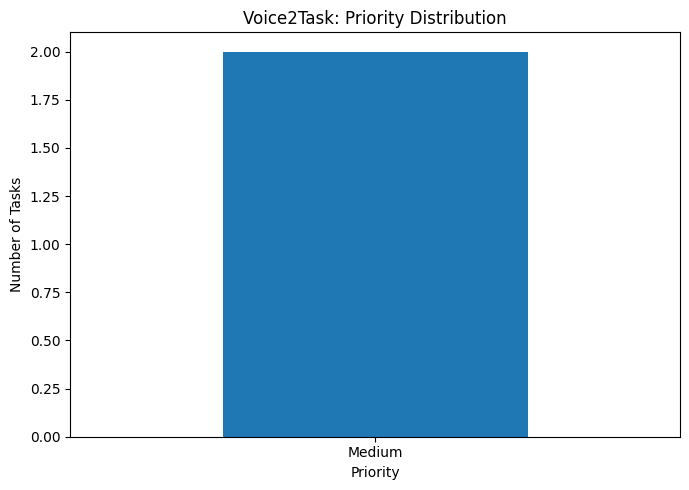

In [62]:
import matplotlib.pyplot as plt

priority_counts = df["Priority"].value_counts()

plt.figure(figsize=(7, 5))
priority_counts.plot(kind="bar")
plt.title("Voice2Task: Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Tasks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

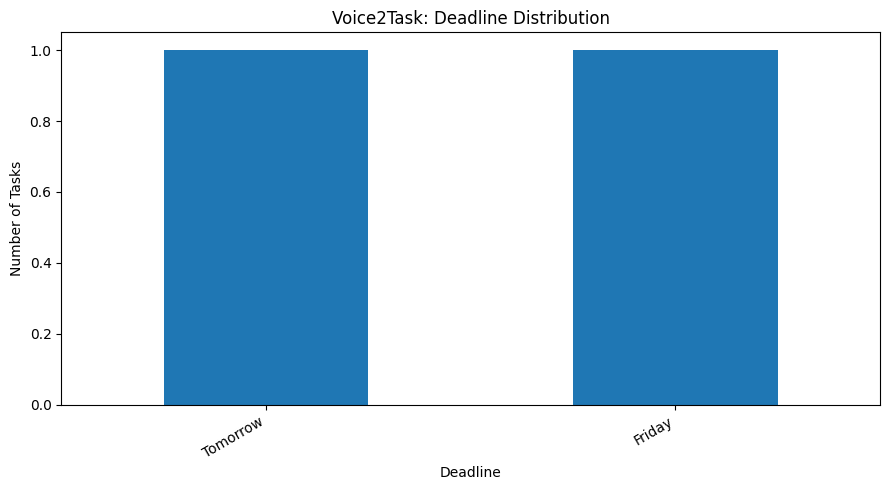

In [63]:
import matplotlib.pyplot as plt

deadline_counts = df["Deadline"].value_counts()

plt.figure(figsize=(9, 5))
deadline_counts.plot(kind="bar")
plt.title("Voice2Task: Deadline Distribution")
plt.xlabel("Deadline")
plt.ylabel("Number of Tasks")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

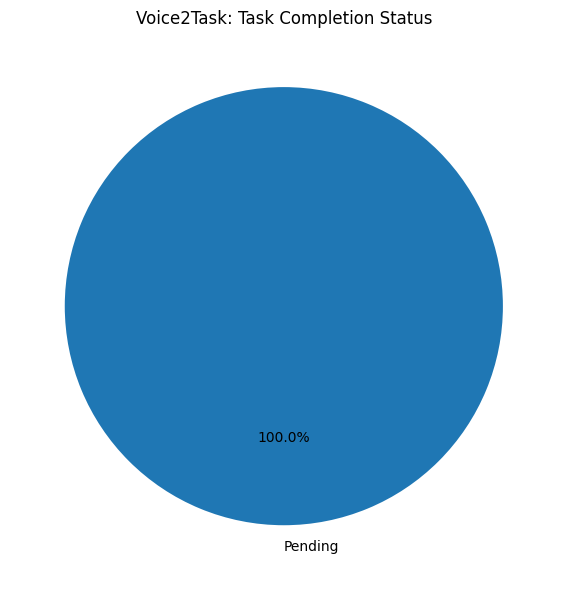

In [64]:
status_counts = df["Completion Status"].value_counts()

plt.figure(figsize=(6, 6))
status_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Voice2Task: Task Completion Status")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [65]:
deadline_tests = [
    {"task": "Complete the assignment tomorrow", "expected_task": "Complete the assignment", "expected_deadline": "Tomorrow"},
    {"task": "Submit the report by Friday", "expected_task": "Submit the report", "expected_deadline": "Friday"},
    {"task": "Finish the project in 2 days", "expected_task": "Finish the project", "expected_deadline": "2 Days"},
    {"task": "Study next week", "expected_task": "Study", "expected_deadline": "Next Week"},
    {"task": "Read the research paper", "expected_task": "Read the research paper", "expected_deadline": "Not specified"},
    {"task": "Call the professor tonight", "expected_task": "Call the professor", "expected_deadline": "Tonight"},
    {"task": "Upload the assignment today", "expected_task": "Upload the assignment", "expected_deadline": "Today"},
    {"task": "Prepare the presentation", "expected_task": "Prepare the presentation", "expected_deadline": "Not specified"},
    {"task": "Complete the project by next week", "expected_task": "Complete the project", "expected_deadline": "Next Week"},
    {"task": "Review the notes later", "expected_task": "Review the notes", "expected_deadline": "Later"}
]

correct = 0

for case in deadline_tests:
    actual_task, actual_deadline = extract_deadline(case["task"])

    if actual_task == case["expected_task"] and actual_deadline == case["expected_deadline"]:
        correct += 1

accuracy = correct / len(deadline_tests) * 100

print("Total test cases:", len(deadline_tests))
print("Correct predictions:", correct)
print("Deadline extraction accuracy:", round(accuracy, 2), "%")

Total test cases: 10
Correct predictions: 10
Deadline extraction accuracy: 100.0 %


In [66]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

actual = [case["expected"] for case in priority_tests]

predicted = [
    classify_priority(case["task"], case["deadline"])
    for case in priority_tests
]

print("Accuracy:", round(accuracy_score(actual, predicted), 3))
print("Macro Precision:", round(precision_score(actual, predicted, average="macro", zero_division=0), 3))
print("Macro Recall:", round(recall_score(actual, predicted, average="macro", zero_division=0), 3))
print("Macro F1-score:", round(f1_score(actual, predicted, average="macro", zero_division=0), 3))
print("\nDetailed Classification Report:\n")
print(classification_report(actual, predicted, zero_division=0))

Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0

Detailed Classification Report:

              precision    recall  f1-score   support

        High       1.00      1.00      1.00         3
         Low       1.00      1.00      1.00         2
      Medium       1.00      1.00      1.00         5

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



In [67]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

evaluation_results = {
    "Accuracy": round(accuracy_score(actual, predicted), 3),
    "Macro Precision": round(precision_score(actual, predicted, average="macro", zero_division=0), 3),
    "Macro Recall": round(recall_score(actual, predicted, average="macro", zero_division=0), 3),
    "Macro F1-score": round(f1_score(actual, predicted, average="macro", zero_division=0), 3)
}

display(pd.DataFrame([evaluation_results]))

,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,1.0,1.0,1.0,1.0
